# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


In [2]:
cell_img = plt.imread('data/cells.png')
cell_img = resize(cell_img, (256, 256))

plt.figure(figsize=(6, 6))
plt.imshow(cell_img, cmap='gray')
plt.show()

<Figure size 600x600 with 1 Axes>

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [3]:
cell_ft = np.fft.fft2(cell_img)
cell_ft.dtype

dtype('complex128')

**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [4]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

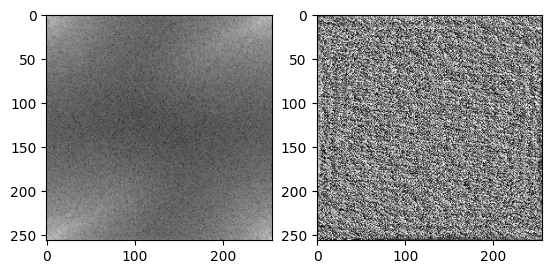

In [5]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


Note for self: shifted it with the command given in the assignments part -->
changed the amplitude and phase accordingly -->
showed it in the same way 

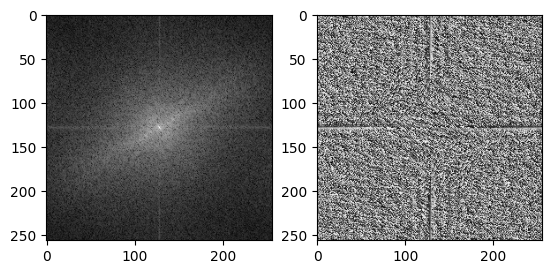

In [6]:
shifted = np.fft.fftshift(cell_ft)

amplitude_shifted = np.abs(shifted)
phase_shifted = np.angle(shifted)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log1p(amplitude_shifted), cmap='gray')

plt.subplot(1, 2, 2)
plt.imshow(phase_shifted, cmap='gray')
plt.show()

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


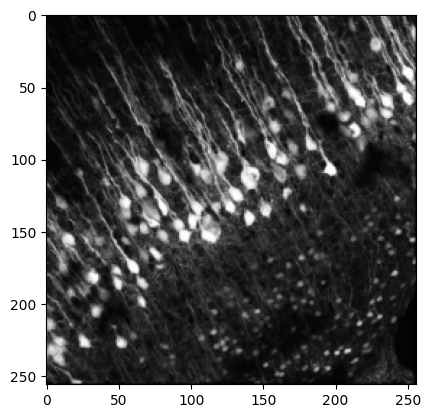

In [7]:
restored = np.fft.ifft2(np.fft.ifftshift(shifted))
plt.figure()
plt.imshow(restored.real, cmap='gray')
plt.show()

---


**[Task 2 (a).]()** Load the brain MR image.


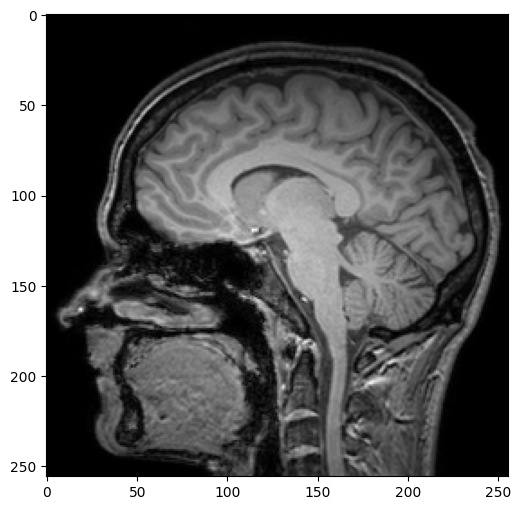

In [8]:
brain = plt.imread('data/brain_mri.png')
plt.figure(figsize=(6, 6))
plt.imshow(brain, cmap='gray')
plt.show()


**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


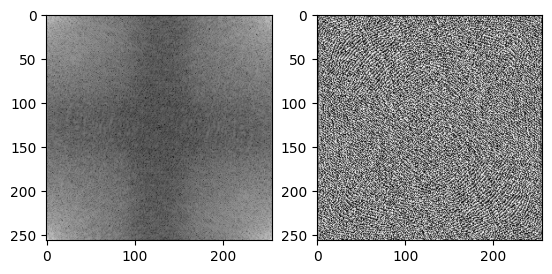

In [9]:
brain_ft = np.fft.fft2(brain)

amplitude = np.abs(brain_ft)
phase = np.angle(brain_ft)

shifted_brain = np.fft.fftshift(brain_ft)

amplitude_shifted_brain = np.abs(shifted_brain)
phase_shifted_brain = np.angle(shifted_brain)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

In [10]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


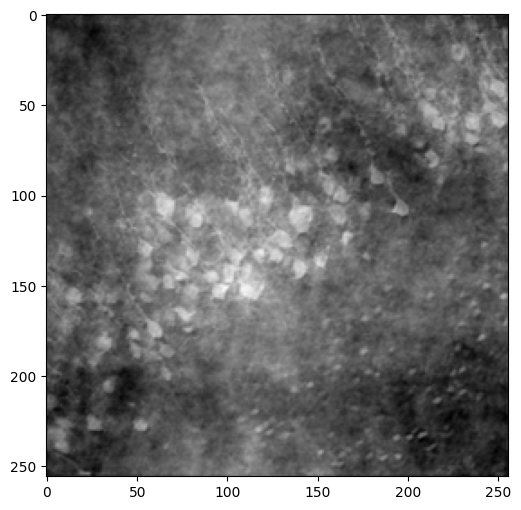

In [11]:
brain_amplitude = np.abs(brain_ft)
cell_phase = np.angle(cell_ft)

merged_ft = to_complex_array(brain_amplitude, cell_phase)
merged_img = np.fft.ifft2(merged_ft).real

plt.figure(figsize=(6, 6))
plt.imshow(merged_img, cmap='gray')
plt.show()

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


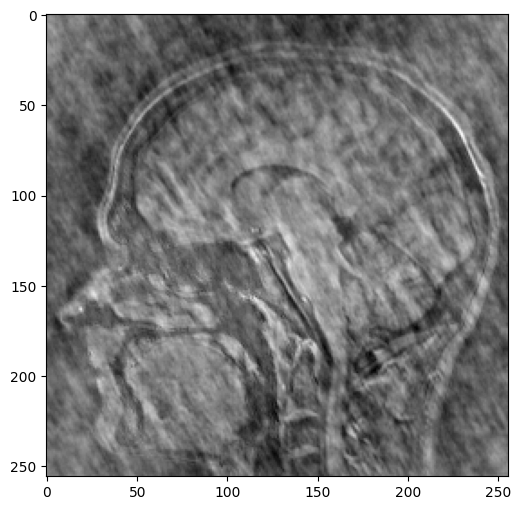

In [12]:
brain_phase = np.angle(brain_ft)
cell_amplitude = np.abs(cell_ft)

merged_ft = to_complex_array(cell_amplitude, brain_phase)
merged_img = np.fft.ifft2(merged_ft).real

plt.figure(figsize=(6, 6))
plt.imshow(merged_img, cmap='gray')
plt.show()

the phase carries more info

---


**[Task 3 (a).]()** Create a lowpass filter mask.


In [18]:
print(brain.shape)

(256, 256)


Bc we know the shape of the brain image, we can create a zeros array with using these dimensions --> und mask i just do it so that it is 50 

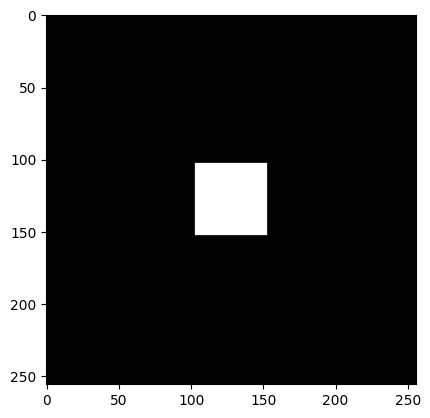

In [ ]:

mask = np.zeros((256, 256))
mask[103:153, 103:153] = 1
plt.imshow(mask, cmap='gray')
plt.show()

**[Task 3 (b).]()** Create a highpass filter maks.


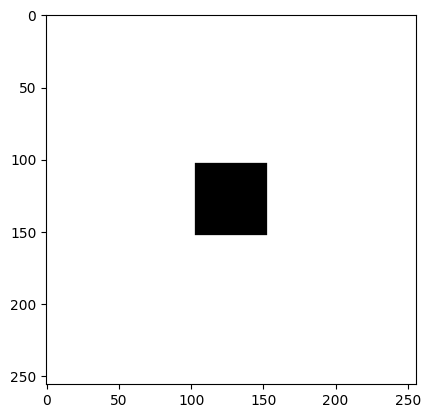

In [26]:
high_pass = 1 - mask
plt.imshow(high_pass, cmap='gray')
plt.show()

Note to self: Low frequencies: slow, gradual changes—like a broad area fading from dark to light. 
High frequencies: rapid changes—like a sharp boundary, tiny details, or speckled noise. 


Low-pass	Low frequencies	Smoother, blurrier image; fine details fade
High-pass	High frequencies	Edges and fine details stand out; broad smooth areas fade

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


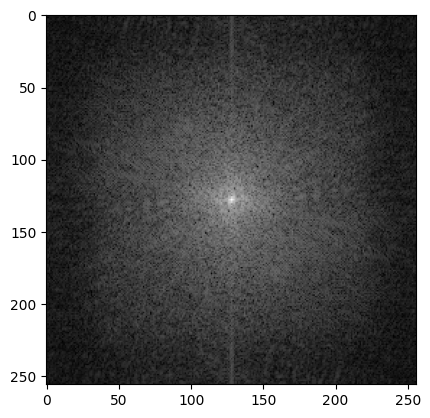

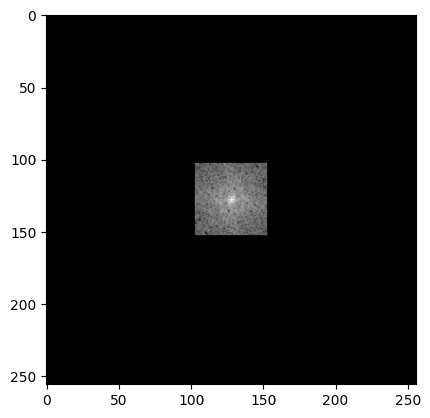

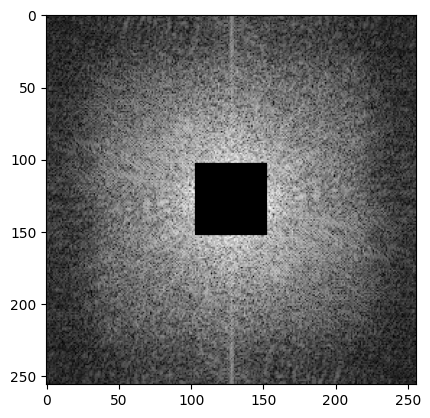

In [38]:
without = amplitude_shifted_brain
low_passs = amplitude_shifted_brain * mask
high_passs = amplitude_shifted_brain * high_pass

plt.imshow(np.log1p(without), cmap='gray')
plt.show()

plt.imshow(np.log1p(low_passs), cmap='gray')
plt.show()

plt.imshow(np.log1p(high_passs), cmap='gray')
plt.show()

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


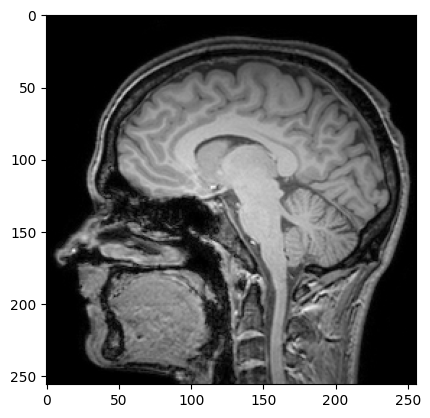

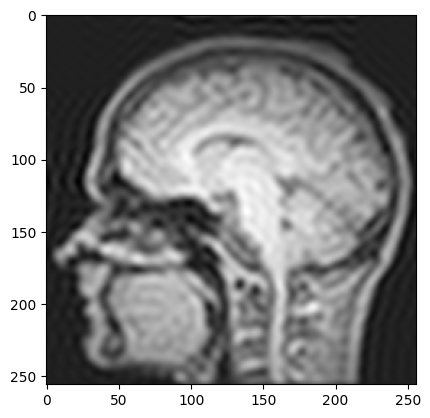

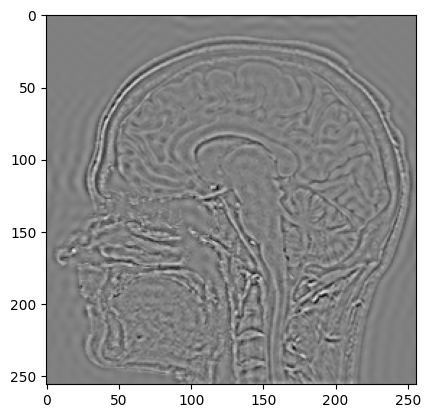

In [43]:
brain_phase_shifted = np.angle(np.fft.fftshift(brain_ft))

merged_filter_without = to_complex_array(without, brain_phase_shifted)
merged_filter_low = to_complex_array(low_passs, brain_phase_shifted)
merged_filter_high = to_complex_array(high_passs, brain_phase_shifted)

restored_without = np.fft.ifft2(np.fft.ifftshift(merged_filter_without)).real
restored_low = np.fft.ifft2(np.fft.ifftshift(merged_filter_low)).real
restored_high = np.fft.ifft2(np.fft.ifftshift(merged_filter_high)).real



plt.imshow(np.log1p(restored_without), cmap='gray')
plt.show()

plt.imshow(np.log1p(restored_low), cmap='gray')
plt.show()

plt.imshow(np.log1p(restored_high), cmap='gray')
plt.show()

---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [49]:
def bok_dft(img):
    M, N = img.shape
    dft = np.zeros(img.shape, dtype=complex)

    for u in range(M):
        for v in range(N):
            total = 0

            for x in range(M):
                for y in range(N):
                    total += img[x, y] * np.exp(
                        -2j * np.pi * (u*x/M + v*y/N)
                    )

            dft[u, v] = total / (M * N)

    return dft

small_img = resize(brain, (16, 16))
result = bok_dft(small_img)
numpy_result = np.fft.fft2(small_img, norm='forward')
print(np.allclose(result, numpy_result))

True


**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [50]:
def bok_dft_idft(dft):
    M, N = dft.shape
    idft = np.zeros(dft.shape, dtype=complex)

    for u in range(M):
        for v in range(N):
            total = 0

            for x in range(M):
                for y in range(N):
                    total += dft[x, y] * np.exp(
                        2j * np.pi * (u*x/M + v*y/N)
                    )

            idft[u, v] = total

    return idft

Due to high computational costs, we need to resize the image.


In [51]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

NameError: name 'brain_img' is not defined

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


**[Task 4 (f).]()** Round the arrays and compare them again.


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
